# 01 · Coleta dos rótulos (Kepler DR25)

Baixa a tabela de KOIs do DR25 pelo serviço TAP do NASA Exoplanet Archive, mantém apenas os registros *Confirmed* e *False Positive* com parâmetros de trânsito completos e salva o resultado em `koi_labels.csv`, usado por todos os notebooks seguintes.

O rótulo vem da coluna `koi_disposition`. A coluna `koi_pdisposition` não serve para este fim, porque nunca assume o valor `CONFIRMED`: os planetas confirmados aparecem nela como `CANDIDATE`.

**Atualização do catálogo.** A coluna `koi_disposition` é atualizada pelo Exoplanet Archive à medida que novos planetas são confirmados. A amostra usada no TCC, obtida em 2026, tem 6.695 KOIs (2.730 confirmados e 3.965 falsos positivos) e está em `koi_labels.csv`, na raiz do repositório. Esta execução, feita depois, encontrou um planeta confirmado a mais (6.696 KOIs). Para reproduzir os resultados do TCC, use o arquivo do repositório.

## 1. Ambiente

No Colab, `pandas`, `requests` e `matplotlib` já vêm instalados. As versões usadas ficam registradas na saída da célula.

In [1]:
import io
import urllib.parse
import requests
import pandas as pd
import matplotlib.pyplot as plt

print("pandas :", pd.__version__)
print("requests:", requests.__version__)

pandas : 2.2.3
requests: 2.32.4


## 2. Consulta ao NASA Exoplanet Archive

Consulta ADQL à tabela `q1_q17_dr25_koi`. Além dos identificadores e do rótulo, são baixados os parâmetros de trânsito usados no *phase-folding* e alguns atributos físicos usados depois na análise de erros.

| Coluna | Significado | Unidade |
|---|---|---|
| `kepid` | Identificador da estrela no Kepler | — |
| `kepoi_name` | Nome do KOI (cada linha é um sinal) | — |
| `koi_disposition` | Disposição no Exoplanet Archive (rótulo usado) | CONFIRMED / FALSE POSITIVE / CANDIDATE |
| `koi_period` | Período orbital | dias |
| `koi_time0bk` | Época do trânsito | BKJD (BJD − 2.454.833,0) |
| `koi_duration` | Duração do trânsito | horas |

In [2]:
TAP_URL = "https://exoplanetarchive.ipac.caltech.edu/TAP/sync"

ADQL = """
SELECT kepid, kepoi_name, kepler_name,
       koi_disposition, koi_pdisposition,
       koi_period, koi_time0bk, koi_duration, koi_depth,
       koi_prad, koi_model_snr, koi_score, koi_steff, koi_srad
FROM q1_q17_dr25_koi
"""

params = {"query": ADQL, "format": "csv"}
url = TAP_URL + "?" + urllib.parse.urlencode(params)

resp = requests.get(url, timeout=120)
resp.raise_for_status()
df = pd.read_csv(io.StringIO(resp.text))

print("Linhas recebidas:", len(df))
df.head()

Linhas recebidas: 8054


,kepid,kepoi_name,kepler_name,koi_disposition,koi_pdisposition,koi_period,koi_time0bk,koi_duration,koi_depth,koi_prad,koi_model_snr,koi_score,koi_steff,koi_srad
0,10811496,K00753.01,NaN,FALSE POSITIVE,FALSE POSITIVE,19.899140,175.850252,1.78220,10829.0,14.60,76.3,0.0,5853.0,0.868
1,10848459,K00754.01,NaN,FALSE POSITIVE,FALSE POSITIVE,1.736952,170.307565,2.40641,8079.2,33.46,505.6,0.0,5805.0,0.791
2,10854555,K00755.01,Kepler-664 b,CONFIRMED,CANDIDATE,2.525592,171.595550,1.65450,603.3,2.75,40.9,1.0,6031.0,1.046
3,10872983,K00756.01,Kepler-228 d,CONFIRMED,CANDIDATE,11.094321,171.201160,4.59450,1517.5,3.90,66.5,1.0,6046.0,0.972
4,10872983,K00756.02,Kepler-228 c,CONFIRMED,CANDIDATE,4.134435,172.979370,3.14020,686.0,2.77,40.2,1.0,6046.0,0.972


In [3]:
# Panorama das disposições no catálogo bruto
df["koi_disposition"].value_counts()

,count
koi_disposition,
FALSE POSITIVE,3965
CONFIRMED,2731
CANDIDATE,1358


## 3. Recortes da amostra

1. mantêm-se apenas os KOIs `CONFIRMED` e `FALSE POSITIVE`; os `CANDIDATE`, ainda sem validação definitiva, são excluídos;
2. descartam-se os KOIs sem período, época ou duração.

O número de registros restantes é impresso a cada passo.

In [4]:
n0 = len(df)

# (1)+(2) manter apenas Confirmed / False Positive (exclui Candidate)
mask_disp = df["koi_disposition"].isin(["CONFIRMED", "FALSE POSITIVE"])
df1 = df[mask_disp].copy()

# (3) exigir parametros de transito nao nulos
params_transito = ["koi_period", "koi_time0bk", "koi_duration"]
mask_params = df1[params_transito].notna().all(axis=1)
df2 = df1[mask_params].copy()

print(f"Bruto ............................ {n0}")
print(f"Apos manter Confirmed/FP ......... {len(df1)}  (excluidos {n0 - len(df1)})")
print(f"Apos exigir parametros de transito {len(df2)}  (excluidos {len(df1) - len(df2)})")

Bruto ............................ 8054
Apos manter Confirmed/FP ......... 6696  (excluidos 1358)
Apos exigir parametros de transito 6696  (excluidos 0)


In [5]:
# Rotulo binario: 1 = planeta confirmado (classe positiva); 0 = falso positivo
df2["label"] = (df2["koi_disposition"] == "CONFIRMED").astype(int)

# Sanidade: cada KOI (kepoi_name) deve ser unico; um mesmo kepid pode ter varios KOIs
assert df2["kepoi_name"].is_unique, "Ha KOIs duplicados — investigar"
print("KOIs unicos:", df2["kepoi_name"].nunique())
print("Estrelas (kepid) distintas:", df2["kepid"].nunique())

KOIs unicos: 6696
Estrelas (kepid) distintas: 5829


## 4. Balanço de classes

As classes são desbalanceadas, com cerca de 41% de planetas confirmados. O balanceamento por SMOTE é feito apenas no conjunto de treino, no notebook 03.

koi_disposition
FALSE POSITIVE    3965
CONFIRMED         2731
Name: count, dtype: int64

Proporcao de positivos (Confirmed): 40.8%


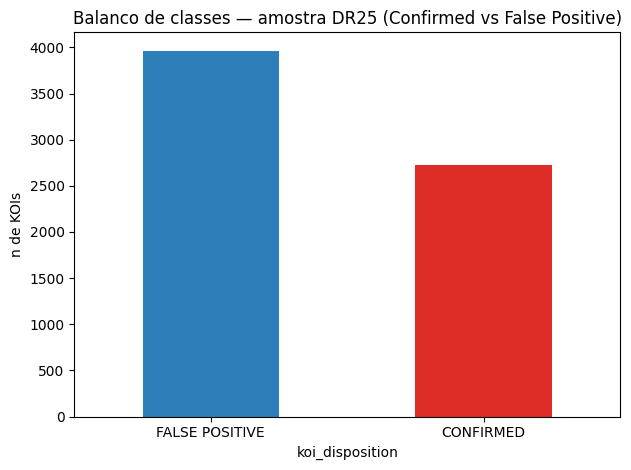

In [6]:
counts = df2["koi_disposition"].value_counts()
frac_pos = df2["label"].mean()
print(counts)
print(f"\nProporcao de positivos (Confirmed): {frac_pos:.1%}")

counts.plot(kind="bar", color=["#2c7fb8", "#de2d26"])
plt.title("Balanco de classes — amostra DR25 (Confirmed vs False Positive)")
plt.ylabel("n de KOIs")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 5. Gravação de `koi_labels.csv`

Por padrão, o arquivo é salvo na pasta da sessão. Para gravá-lo no Google Drive, onde os notebooks seguintes o procuram, basta descomentar as linhas de montagem. Se o arquivo não estiver no Drive, o notebook 02 o gera de novo com a mesma consulta.

In [7]:
import os
# from google.colab import drive
# drive.mount('/content/drive')
# OUT_DIR = '/content/drive/MyDrive/TCC-Exoplanetas'
OUT_DIR = '.'
os.makedirs(OUT_DIR, exist_ok=True)  # cria a pasta se ela ainda nao existir

cols_out = [
    "kepid", "kepoi_name", "kepler_name", "koi_disposition", "label",
    "koi_period", "koi_time0bk", "koi_duration", "koi_depth",
    "koi_prad", "koi_model_snr", "koi_score", "koi_steff", "koi_srad",
]

out_path = f"{OUT_DIR}/koi_labels.csv"
df2[cols_out].to_csv(out_path, index=False)
print("Salvo em:", os.path.abspath(out_path))
print("Linhas:", len(df2))
df2[cols_out].head()

Salvo em: /content/koi_labels.csv
Linhas: 6696


,kepid,kepoi_name,kepler_name,koi_disposition,label,koi_period,koi_time0bk,koi_duration,koi_depth,koi_prad,koi_model_snr,koi_score,koi_steff,koi_srad
0,10811496,K00753.01,NaN,FALSE POSITIVE,0,19.899140,175.850252,1.78220,10829.0,14.60,76.3,0.0,5853.0,0.868
1,10848459,K00754.01,NaN,FALSE POSITIVE,0,1.736952,170.307565,2.40641,8079.2,33.46,505.6,0.0,5805.0,0.791
2,10854555,K00755.01,Kepler-664 b,CONFIRMED,1,2.525592,171.595550,1.65450,603.3,2.75,40.9,1.0,6031.0,1.046
3,10872983,K00756.01,Kepler-228 d,CONFIRMED,1,11.094321,171.201160,4.59450,1517.5,3.90,66.5,1.0,6046.0,0.972
4,10872983,K00756.02,Kepler-228 c,CONFIRMED,1,4.134435,172.979370,3.14020,686.0,2.77,40.2,1.0,6046.0,0.972


## Próximo passo

O notebook 02 testa o pré-processamento em cinco alvos antes de processar a amostra inteira.

Unidades: `koi_period` em dias, `koi_duration` em horas (dividir por 24 para obter dias) e `koi_time0bk` em BKJD, o mesmo referencial de tempo das curvas do Kepler no Lightkurve.